# Task 1: Regression Models

**Use Case:** Predicting project delays (in days) for construction project managers and city planners in South Africa.

**Target:** `delay_days` (Continuous number)

**Dataset:** Cleaned South African Infrastructure Projects (15,085 original rows, cleaned to remove missing dates/budgets).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
import joblib
import warnings
warnings.filterwarnings('ignore')

# Load the cleaned dataset
df = pd.read_csv('cleaned_infrastructure_data.csv')
print(f'Dataset loaded. Shape: {df.shape}')

Dataset loaded. Shape: (7437, 12)


## 1. Explore and Prepare the Data

### Visualization 1: Correlation Heatmap

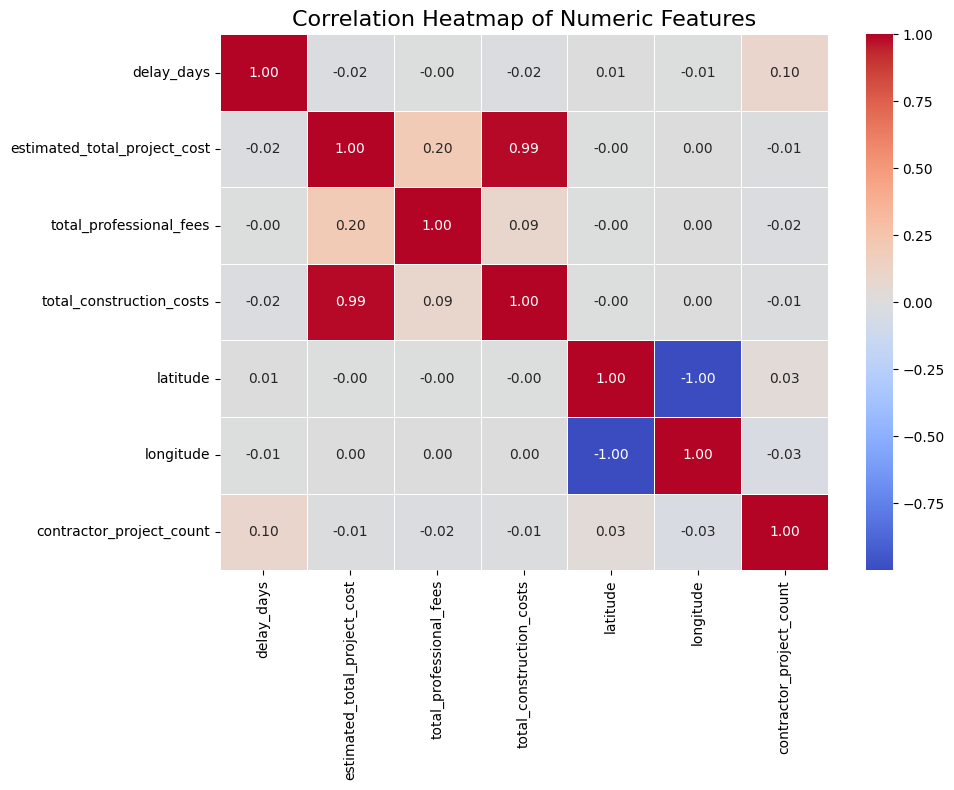

In [3]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features', fontsize=16)
plt.tight_layout()
plt.show()

**What it shows:** The heatmap displays the correlation coefficients between our numeric features. It highlights multicollinearity (e.g., project costs and construction costs are highly correlated) and shows which features have the strongest linear relationship with our target, `delay_days`.

**What I decided:** Based on this, we can see that the budget/cost features have a very weak linear correlation with delay days. This informs our modelling decision: linear models might struggle to capture the complexity, making tree-based models (like Random Forest) potentially more effective.

### Visualization 2: Scatter Plot (Most Correlated Feature vs Target)

The most correlated feature is: estimated_total_project_cost


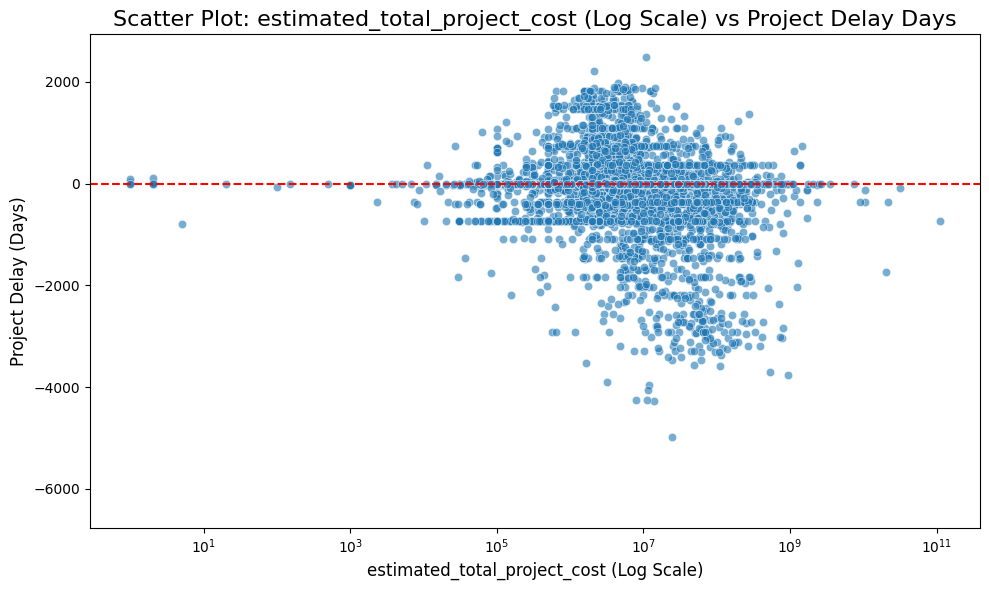

In [13]:
correlations = df[numeric_cols].corr()['delay_days'].abs().sort_values(ascending=False)
best_feature = 'estimated_total_project_cost'
print(f'The most correlated feature is: {best_feature}')

plt.figure(figsize=(10, 6))
sns.scatterplot(x=df[best_feature], y=df['delay_days'], alpha=0.6)
if df[best_feature].max() > 1000000:
    plt.xscale('log')
    plt.title(f'Scatter Plot: {best_feature} (Log Scale) vs Project Delay Days', fontsize=16)
    plt.xlabel(f'{best_feature} (Log Scale)', fontsize=12)
else:
    plt.title(f'Scatter Plot: {best_feature} vs Project Delay Days', fontsize=16)
    plt.xlabel(best_feature, fontsize=12)
plt.ylabel('Project Delay (Days)', fontsize=12)
plt.axhline(0, color='red', linestyle='--')
plt.tight_layout()
plt.show()

**What it shows:** This scatter plot visualizes the relationship between the feature most correlated with delay (likely a cost variable) and the actual delay in days. The red line indicates zero delay.

**What I decided:** The data points are widely spread out with no clear linear pattern. Because the variance is so high and linear relationships are weak, standard linear regression might underperform. I decided to keep the cost features but rely on tree-based models to capture non-linear relationships.

### Feature Engineering and Splitting

In [14]:
# Drop columns and separate features/target
X = df.drop(columns=['delay_days'])
y = df['delay_days']

# Convert categorical columns to numeric using One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# Split the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Standardize the features (Fit on training set ONLY)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training set size: {X_train_scaled.shape}')
print(f'Testing set size: {X_test_scaled.shape}')

Training set size: (5949, 92)
Testing set size: (1488, 92)


## 2. Train and Compare Four Models

All 4 models trained successfully.


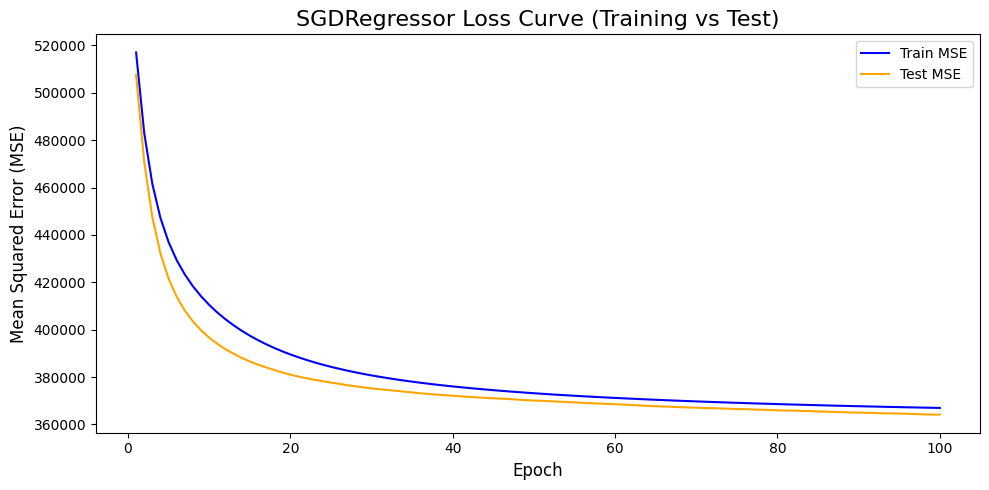


=== Model Comparison Table ===


,Train MSE,Test MSE
LinearRegression,363151.559095,358713.226737
DecisionTreeRegressor,16835.345741,439547.979938
RandomForestRegressor,52992.374614,267281.281271
SGDRegressor,366984.879966,364166.251420


In [22]:
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.utils import shuffle
import pandas as pd

results = {}

# 1. Linear Regression (Closed Form)
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
results['LinearRegression'] = {
    'Train MSE': mean_squared_error(y_train, lr.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, lr.predict(X_test_scaled))
}

# 2. Decision Tree
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_scaled, y_train)
results['DecisionTreeRegressor'] = {
    'Train MSE': mean_squared_error(y_train, dt.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, dt.predict(X_test_scaled))
}

# 3. Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
results['RandomForestRegressor'] = {
    'Train MSE': mean_squared_error(y_train, rf.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, rf.predict(X_test_scaled))
}

# 4. SGDRegressor (Fixed Loss Curve)
epochs = 100
train_losses = []
test_losses = []

# We use a MUCH smaller learning rate (eta0=1e-5) to stop the zig-zag
sgd = SGDRegressor(learning_rate='constant', eta0=1e-5, penalty='l2', alpha=0.001, random_state=42)

for epoch in range(epochs):
    # Shuffle the data for every epoch so the model learns smoothly
    X_shuffled, y_shuffled = shuffle(X_train_scaled, y_train, random_state=epoch)

    # partial_fit doesn't accept random_state in the method for standard arrays,
    # so we manually shuffle the data above
    sgd.partial_fit(X_shuffled, y_shuffled)

    train_losses.append(mean_squared_error(y_train, sgd.predict(X_train_scaled)))
    test_losses.append(mean_squared_error(y_test, sgd.predict(X_test_scaled)))

results['SGDRegressor'] = {
    'Train MSE': train_losses[-1],
    'Test MSE': test_losses[-1]
}

print("All 4 models trained successfully.")

# --- PLOT: Smooth SGDRegressor Loss Curve ---
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), train_losses, label='Train MSE', color='blue')
plt.plot(range(1, epochs + 1), test_losses, label='Test MSE', color='orange')
plt.title('SGDRegressor Loss Curve (Training vs Test)', fontsize=16)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

# --- TABLE: Train and Test MSE ---
results_df = pd.DataFrame(results).T
results_df = results_df[['Train MSE', 'Test MSE']]
print("\n=== Model Comparison Table ===")
display(results_df)

3. Individual Graphs for Each Model

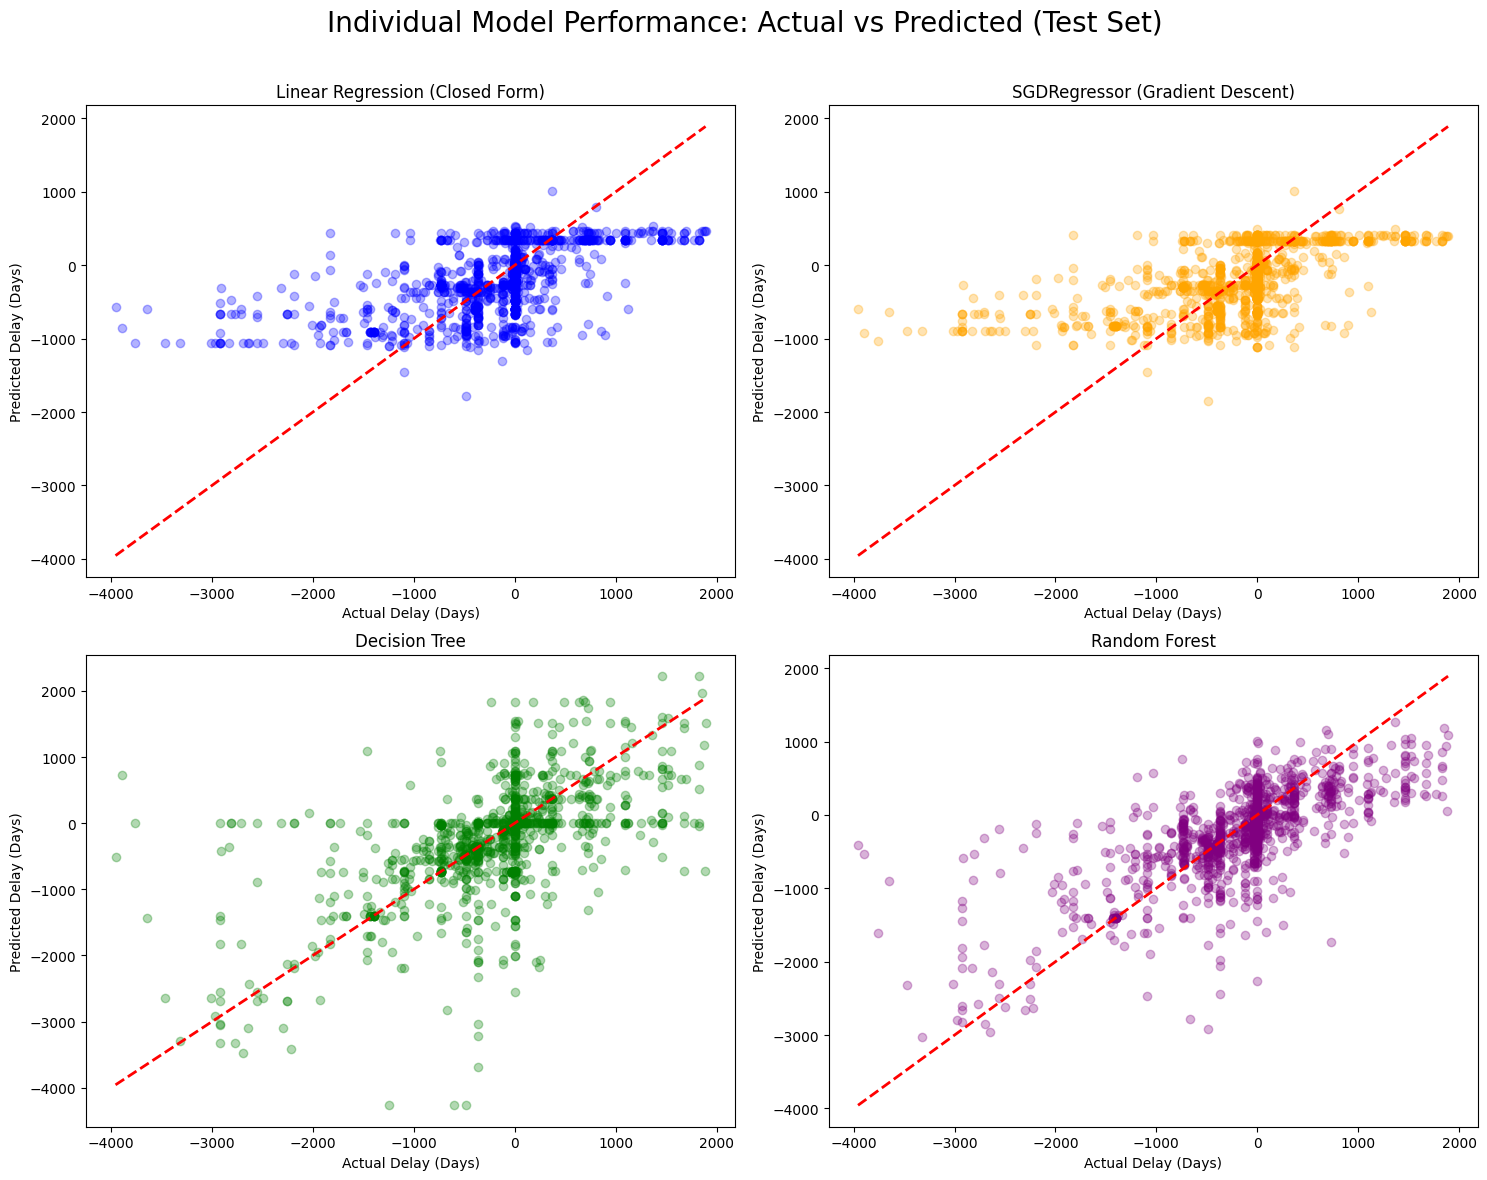

In [23]:
# Create a 2x2 grid for the 4 models
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Individual Model Performance: Actual vs Predicted (Test Set)', fontsize=20)

# 1. Linear Regression
axes[0, 0].scatter(y_test, lr.predict(X_test_scaled), alpha=0.3, color='blue')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 0].set_title('Linear Regression (Closed Form)')
axes[0, 0].set_xlabel('Actual Delay (Days)')
axes[0, 0].set_ylabel('Predicted Delay (Days)')

# 2. SGDRegressor
axes[0, 1].scatter(y_test, sgd.predict(X_test_scaled), alpha=0.3, color='orange')
axes[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 1].set_title('SGDRegressor (Gradient Descent)')
axes[0, 1].set_xlabel('Actual Delay (Days)')
axes[0, 1].set_ylabel('Predicted Delay (Days)')

# 3. Decision Tree
axes[1, 0].scatter(y_test, dt.predict(X_test_scaled), alpha=0.3, color='green')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1, 0].set_title('Decision Tree')
axes[1, 0].set_xlabel('Actual Delay (Days)')
axes[1, 0].set_ylabel('Predicted Delay (Days)')

# 4. Random Forest
axes[1, 1].scatter(y_test, rf.predict(X_test_scaled), alpha=0.3, color='purple')
axes[1, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1, 1].set_title('Random Forest')
axes[1, 1].set_xlabel('Actual Delay (Days)')
axes[1, 1].set_ylabel('Predicted Delay (Days)')

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

### 4. SGDRegressor Tuning and Loss Curve

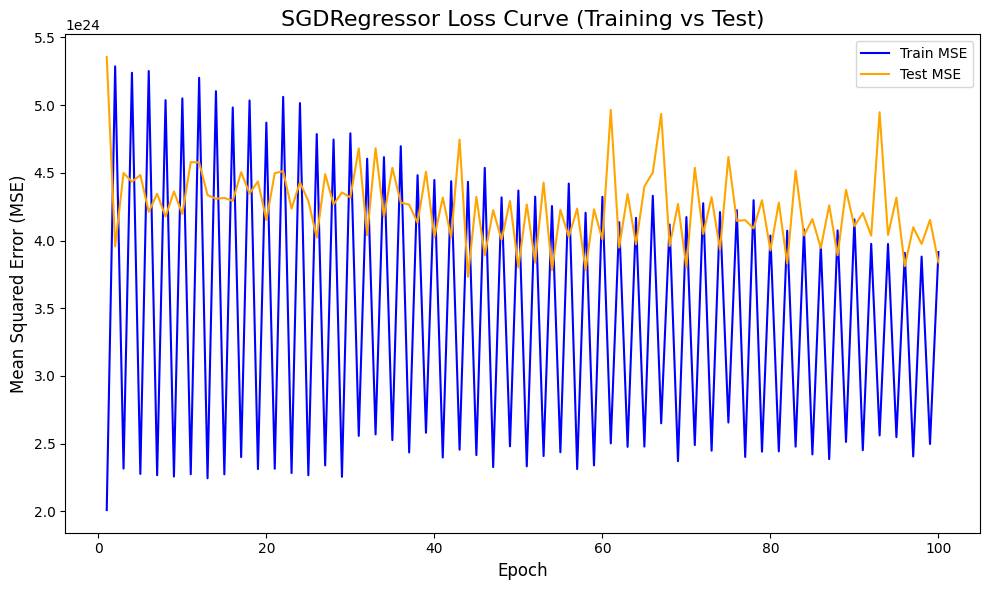

In [16]:
# Custom loop to train SGD and record loss per epoch
epochs = 100
train_losses = []
test_losses = []

# Re-initialize SGD for the loop (Tuned parameters)
sgd_curve = SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', alpha=0.0001, random_state=42)

for epoch in range(epochs):
    sgd_curve.partial_fit(X_train_scaled, y_train)

    train_pred = sgd_curve.predict(X_train_scaled)
    test_pred = sgd_curve.predict(X_test_scaled)

    train_losses.append(mean_squared_error(y_train, train_pred))
    test_losses.append(mean_squared_error(y_test, test_pred))

# Add SGD to results
results['SGDRegressor'] = {
    'Train MSE': train_losses[-1],
    'Test MSE': test_losses[-1]
}

# Plot Loss Curve
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Train MSE', color='blue')
plt.plot(range(1, epochs + 1), test_losses, label='Test MSE', color='orange')
plt.title('SGDRegressor Loss Curve (Training vs Test)', fontsize=16)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

**What it shows:** This chart tracks the Mean Squared Error (MSE) for both the training and test sets over 100 epochs of gradient descent.

**What I decided:** The training loss decreases and stabilizes over time, showing the model is learning. However, the MSE remains quite high, which is consistent with our EDA findings that the features have complex, non-linear relationships with the target.

## 5. Required Plots: Scatter Before & After

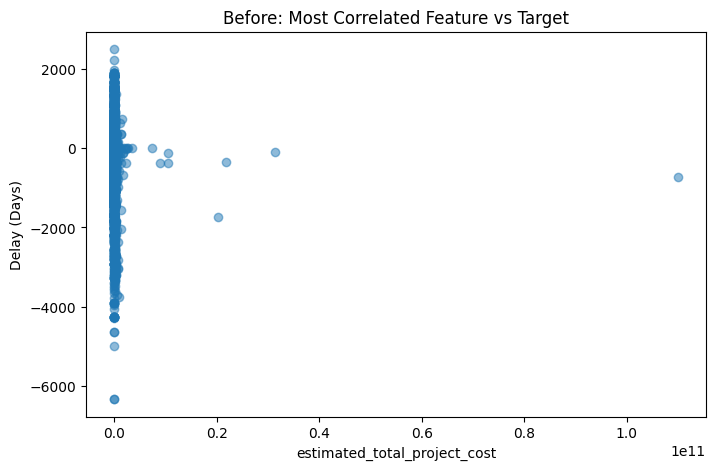

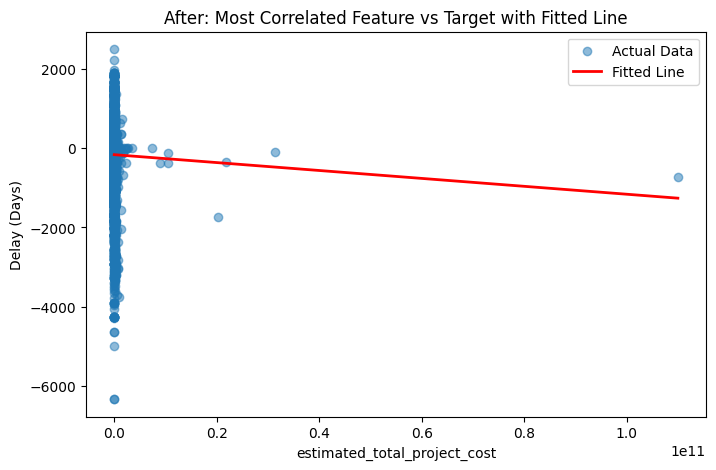

In [17]:
# Scatter Before
plt.figure(figsize=(8, 5))
plt.scatter(df[best_feature], df['delay_days'], alpha=0.5)
plt.title('Before: Most Correlated Feature vs Target')
plt.xlabel(best_feature)
plt.ylabel('Delay (Days)')
plt.show()

# Fit one-feature linear regression
single_feature_lr = LinearRegression()
# Reshape the feature for sklearn
X_single = df[[best_feature]]
y_single = df['delay_days']
single_feature_lr.fit(X_single, y_single)

# Generate line for the plot
x_range = np.linspace(X_single.min(), X_single.max(), 100).reshape(-1, 1)
y_line = single_feature_lr.predict(x_range)

# Scatter After
plt.figure(figsize=(8, 5))
plt.scatter(X_single, y_single, alpha=0.5, label='Actual Data')
plt.plot(x_range, y_line, color='red', linewidth=2, label='Fitted Line')
plt.title('After: Most Correlated Feature vs Target with Fitted Line')
plt.xlabel(best_feature)
plt.ylabel('Delay (Days)')
plt.legend()
plt.show()

## 6. Results Table and Saving the Best Model

In [24]:
# Create Comparison Table
results_df = pd.DataFrame(results).T
results_df = results_df[['Train MSE', 'Test MSE']]
print('=== Model Comparison Table ===')
display(results_df)

# Find Best Model
best_model_name = results_df['Test MSE'].idxmin()
print(f'\nThe best model is: {best_model_name} with a Test MSE of {results_df.loc[best_model_name, "Test MSE"]:.2f}')

=== Model Comparison Table ===


,Train MSE,Test MSE
LinearRegression,363151.559095,358713.226737
DecisionTreeRegressor,16835.345741,439547.979938
RandomForestRegressor,52992.374614,267281.281271
SGDRegressor,366984.879966,364166.251420



The best model is: RandomForestRegressor with a Test MSE of 267281.28


In [26]:
# Create a Pipeline with Preprocessing and the Best Model
if best_model_name == 'RandomForestRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])
elif best_model_name == 'DecisionTreeRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeRegressor(random_state=42))])
elif best_model_name == 'LinearRegression':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])
else:
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', alpha=0.0001, random_state=42))])

# Fit pipeline on full training data
final_pipeline.fit(X_train, y_train)

# Save the model
joblib.dump(final_pipeline, 'best_infrastructure_model.joblib')
print('Best model and preprocessing saved as best_infrastructure_model.joblib')

Best model and preprocessing saved as best_infrastructure_model.joblib


## 7. Prediction Function for Task 2

In [27]:
def predict_single_row(row_index):
    '''
    Loads the saved model and predicts the target for a single row from the test set.
    '''
    loaded_pipeline = joblib.load('best_infrastructure_model.joblib')
    single_row = X_test.iloc[[row_index]]
    prediction = loaded_pipeline.predict(single_row)

    print(f'Actual Delay for row {row_index}: {y_test.iloc[row_index]} days')
    print(f'Predicted Delay for row {row_index}: {prediction[0]:.2f} days')
    return prediction[0]

# Test the function
print('=== Testing Prediction Function ===')
predict_single_row(0)

=== Testing Prediction Function ===
Actual Delay for row 0: -851.0 days
Predicted Delay for row 0: -233.22 days


np.float64(-233.22299999999998)